# **Silhouette Score**  

## **Overview**  
- The **Silhouette Score** is a metric used to evaluate the **quality of clustering**.  
- It measures how **similar a data point is to its own cluster** compared to other clusters.  
- The score ranges from **-1 to 1**:  
  - **1** → Best clustering (well-separated clusters).  
  - **0** → Overlapping clusters (ambiguous clustering).  
  - **-1** → Worst clustering (wrong cluster assignment).  

---

## **Why Use Silhouette Score?**  
✅ **Evaluates clustering quality** → Determines how well data points fit in clusters.  
✅ **Compares different clustering methods** (K-Means, DBSCAN, Hierarchical, etc.).  
✅ **Helps in selecting the optimal number of clusters (K)** in K-Means.  
✅ **Works with different distance metrics** (Euclidean, Manhattan, etc.).  

---

## **When to Use Silhouette Score?**  
🔹 **Choosing the best K** in K-Means clustering.  
🔹 **Evaluating clustering algorithms** (K-Means vs. Hierarchical vs. DBSCAN).  
🔹 **Detecting poor cluster assignments** (negative silhouette values).  

---

## **Limitations**  
❌ **Not effective for density-based clusters (e.g., DBSCAN)**.  
❌ **Computationally expensive** for large datasets.  
❌ **Sensitive to distance metrics** (may need tuning for different datasets).  

---

## **Conclusion**  
- **Higher silhouette scores indicate better clustering**.  
- **Use it to compare multiple clustering algorithms and find the optimal K**.  
- **Not ideal for DBSCAN or clusters with varying densities**. 

---

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("../datasets/Iris_unlabeled.csv")
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


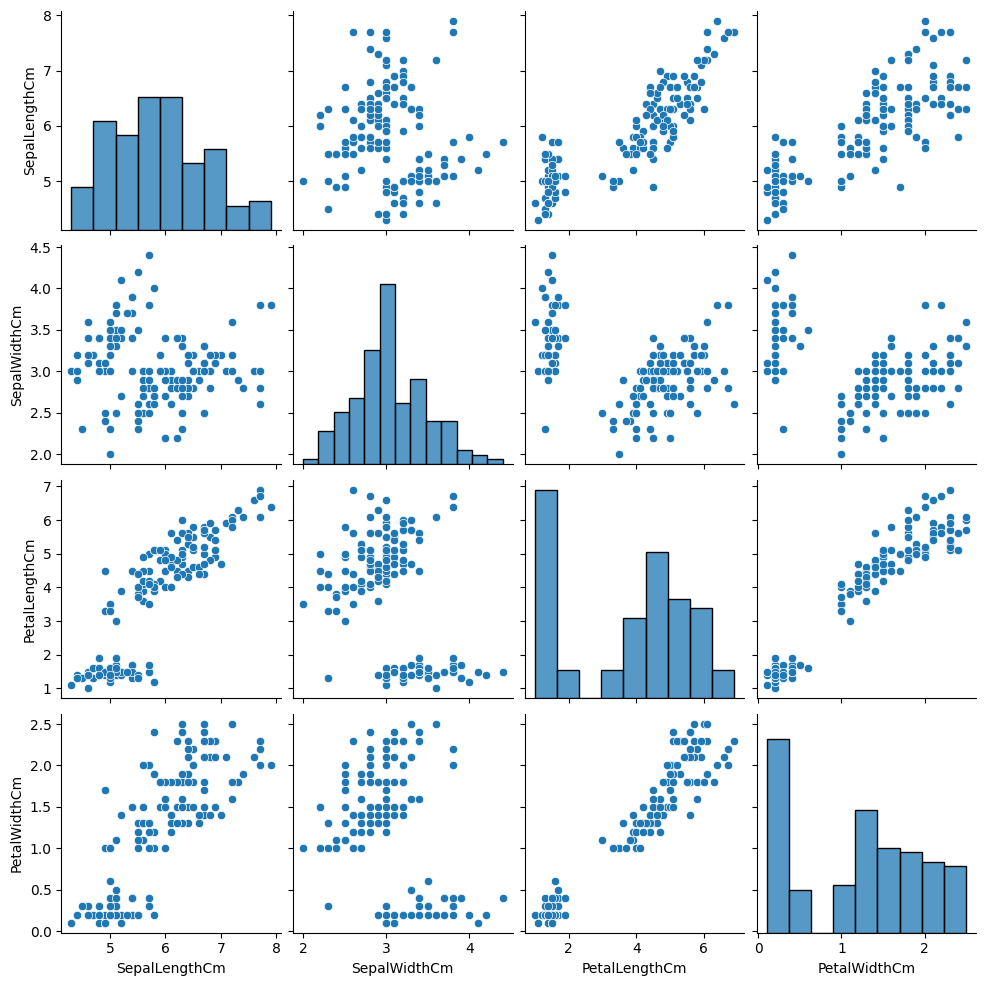

In [3]:
sns.pairplot(data=df)
plt.show()

In [4]:
wcss = []

for i in range(2, 21):
    km = KMeans(n_clusters=i, init='k-means++')
    km.fit(df)
    wcss.append(km.inertia_)    # interia is the wcss value

# wcss

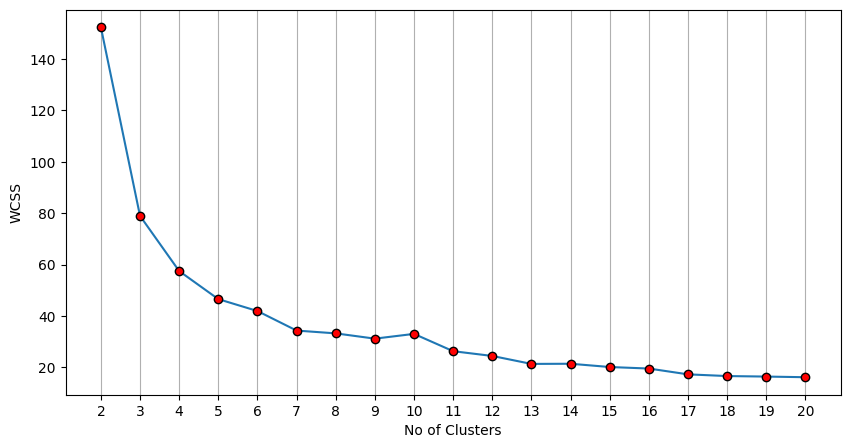

In [5]:
plt.figure(figsize=(10,5))

plt.plot([i for i in range(2, 21)], wcss, marker='o', markerfacecolor='red', markeredgecolor='black')

plt.xticks([i for i in range(2, 21)])

plt.xlabel("No of Clusters")
plt.ylabel("WCSS")

plt.grid(axis='x')
plt.show()

Here we are having confusion on selecting the best value of k, so to solve this we eill be using thw **Silhouettee Score**

In [6]:
ss = []

for i in range(2, 21):
    km = KMeans(n_clusters=i, init='k-means++')
    km.fit(df)
    ss.append(silhouette_score(df, labels=km.labels_)) 

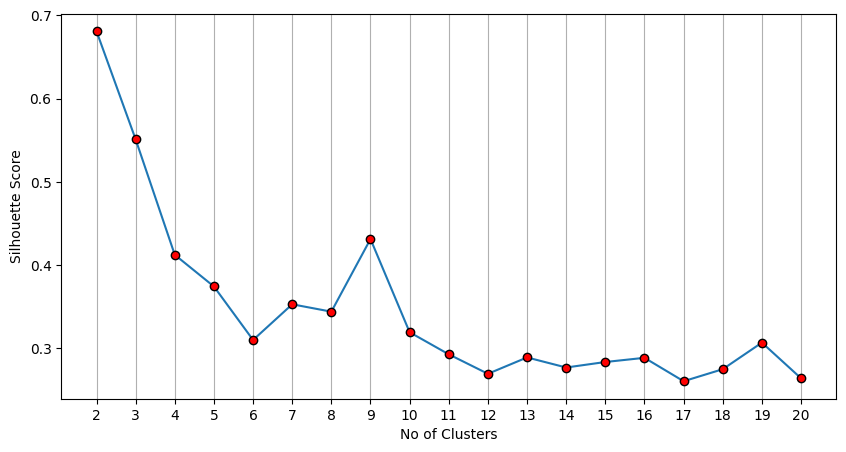

In [7]:
plt.figure(figsize=(10,5))

plt.plot([i for i in range(2, 21)], ss, marker='o', markerfacecolor='red', markeredgecolor='black')

plt.xticks([i for i in range(2, 21)])

plt.xlabel("No of Clusters")
plt.ylabel("Silhouette Score")

plt.grid(axis='x')
plt.show()

From  above we can see that see that the we are getting maximum Silhouette Sscore for k=2, means for k=2 model will be best 

In [8]:
kmc = KMeans(n_clusters=2)
kmc.fit_predict(df)

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [9]:
df['predict'] = kmc.fit_predict(df)
df.head(3)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,predict
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0


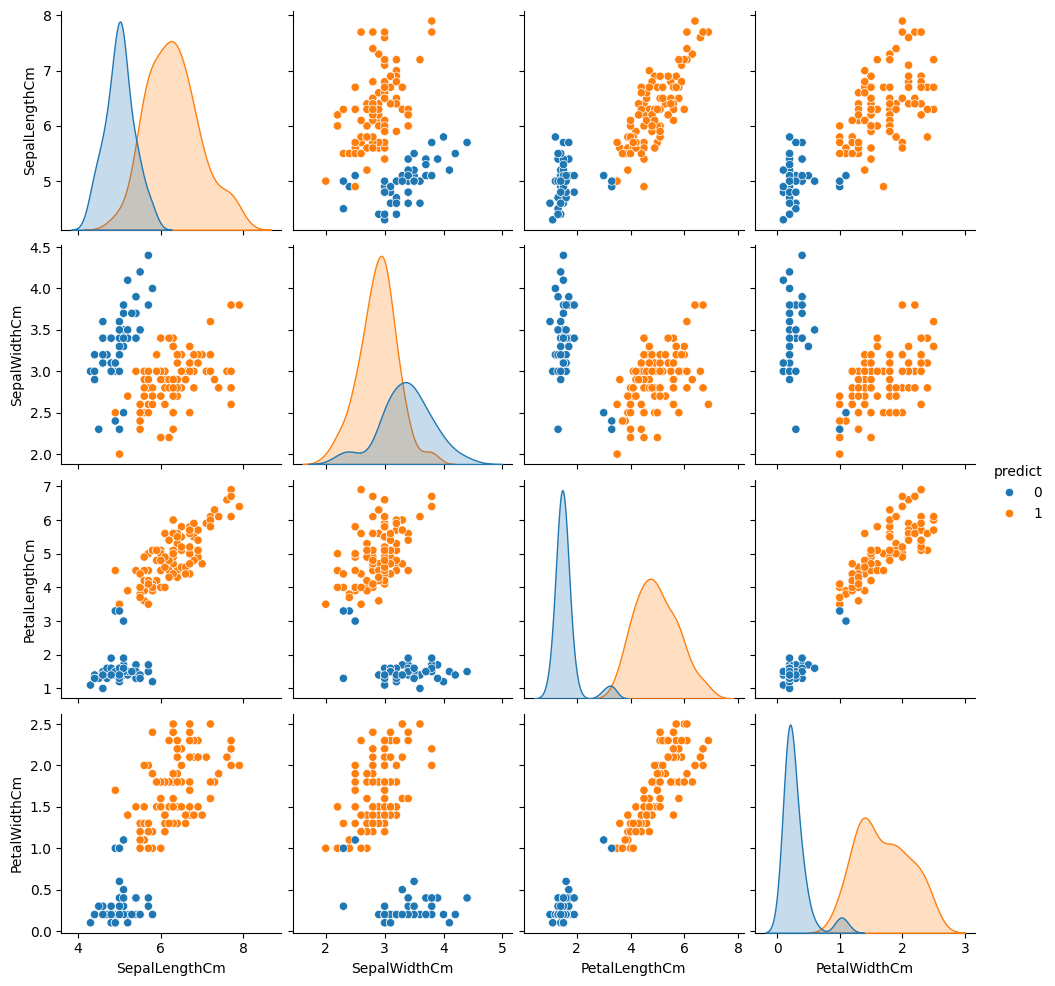

In [10]:
sns.pairplot(data=df, hue='predict')
plt.show()

---